# 01b · EDA — 경기 (games, players, career, game_tracking ×3, player_play)

**목적**: Stage 3(루키 시즌 경기 집계) 전에 데이터 구조와 키 관계를 확인하고, 다음 단계가 쓸 **정의·기준값을 근거와 함께 확정**한다.

| 입력 | 산출물 |
|---|---|
| `games`, `players`, `player_career_successes`, `game_tracking_2023/24/25`, `player_play` (+ `combine_results`의 포지션·forty) | ① 결정값: season 부여 방식, 루키 시즌 정의, 경기 트래킹 글리치 임계값, 최소 노출 기준, `starter_flag` 기준 ② `reports/tables/1_*.csv` ③ `reports/figures/1_*.png` ④ 12절 요약 → `reports/eda.md` |

이 노트북은 `data/processed/`에 아무것도 쓰지 않는다. 트래킹 2GB는 4절에서 **필요한 컬럼만 chunk로 한 번** 읽어 메모리 안의 요약 테이블로 만든다.

## 0. 환경 설정

In [1]:
import os, sys
from pathlib import Path

try:                                    # Colab
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/nfl-bdb2027')
except ImportError:                     # 로컬 VS Code (notebooks/에서 실행)
    ROOT = Path.cwd().parent

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from src import config
config.setup()

[config] PROJECT_ROOT = /Users/pyeon-yeyeong/nfl-bdb2027
[config] DATA_DIR     = /Users/pyeon-yeyeong/nfl-bdb2027/data
        python: 3.14.6
      platform: macOS-26.5.1-arm64-arm-64bit-Mach-O
         colab: no
         numpy: 2.4.6
        pandas: 3.0.3
         scipy: 1.18.0
  scikit-learn: 1.9.0
    matplotlib: 3.11.0
       seaborn: 0.13.2
       pyarrow: 23.0.1
        joblib: 1.5.3
          tqdm: 4.68.2


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.9)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

POS = config.POSITION_GROUPS            # ["DB", "OL", "DL", "WR", "TE"]
# 그림 안 글자는 영어로 둔다 (Colab·Mac 모두 한글 폰트 설정 없이 깨지지 않게)


def save_fig(fig, name):
    path = config.fig_path(1, name)
    fig.savefig(path, dpi=config.FIG_DPI, bbox_inches="tight")
    print(f"saved → {path.relative_to(ROOT)}")


def save_table(df, name, index=True):
    path = config.TABLES_DIR / f"1_{name}.csv"
    df.to_csv(path, index=index)
    print(f"saved → {path.relative_to(ROOT)}")

## 1. games — 시즌 · 경기 유형
프로파일 기준: 시즌마다 PRE 49 / REG 272 / POST 13 = 334경기.

In [3]:
games = pd.read_csv(config.RAW_FILES["games"])
print(games.shape, "| game_id 중복:", games["game_id"].duplicated().sum())
season_tbl = games.groupby(["season", "season_type"]).size().unstack()[["PRE", "REG", "POST"]]
save_table(season_tbl, "game_games_by_season")
season_tbl

(1002, 7) | game_id 중복: 0
saved → reports/tables/1_game_games_by_season.csv


season_type,PRE,REG,POST
season,,,
2023,49,272,13
2024,49,272,13
2025,49,272,13


In [4]:
# 함정 확인: game_id 앞 4자리는 '경기 날짜의 연도'이지 시즌이 아니다 (1~2월 플레이오프는 다음 해 숫자)
prefix = games["game_id"].astype(str).str[:4].astype(int).rename("game_id_prefix")
pd.crosstab(prefix, [games["season"], games["season_type"]])

season         2023          2024          2025         
season_type    POST PRE  REG POST PRE  REG POST PRE  REG
game_id_prefix                                          
2023              0  49  256    0   0    0    0   0    0
2024             13   0   16    0  49  256    0   0    0
2025              0   0    0   13   0   16    0  49  256
2026              0   0    0    0   0    0   13   0   16

> **결정**: season은 항상 `games.csv`를 조인해서 붙인다. game_id에서 연도를 잘라 쓰면 플레이오프가 다음 시즌으로 잘못 분류된다.

## 2. players — 드래프트 · 포지션
분석 그룹은 `combine_results.combine_position`(DB/OL/DL/WR/TE)을 쓴다. `players.nfl_position`과의 대응을 확인한다.

In [5]:
players = pd.read_csv(config.RAW_FILES["players"])
cr = pd.read_csv(config.RAW_FILES["combine_results"], usecols=["nfl_id", "combine_position", "forty"])
players = players.merge(cr[["nfl_id", "combine_position"]], on="nfl_id", how="left")

tier = pd.cut(players["draft_round"], bins=[0, 3, 7], labels=["1-3R", "4-7R"])
players["draft_tier"] = tier.cat.add_categories("UDFA").fillna("UDFA")

print(players.shape, "| combine_position 매칭 실패:", players["combine_position"].isna().sum())
display(players["draft_year"].value_counts().sort_index().to_frame("n"))

tier_tbl = pd.crosstab(players["combine_position"], players["draft_tier"], margins=True)
tier_tbl = tier_tbl.reindex(POS + ["All"])[["1-3R", "4-7R", "UDFA", "All"]]
save_table(tier_tbl, "game_draft_tier_by_position")
tier_tbl

(510, 12) | combine_position 매칭 실패: 0


,n
draft_year,
2023,160
2024,177
2025,173


saved → reports/tables/1_game_draft_tier_by_position.csv


draft_tier,1-3R,4-7R,UDFA,All
combine_position,,,,
DB,34,63,25,122
OL,46,43,32,121
DL,36,53,29,118
WR,32,45,30,107
TE,8,23,11,42
All,156,227,127,510


In [6]:
# 실제 NFL 포지션 → 분석 그룹 대응 (OLB는 DL 그룹 = EDGE 역할, FB는 TE, ILB/MLB/RB 일부는 DB)
pd.crosstab(players["nfl_position"], players["combine_position"])[POS]

combine_position,DB,OL,DL,WR,TE
nfl_position,,,,,
C,0,20,0,0,0
CB,60,0,0,0,0
DB,5,0,0,0,0
DE,0,0,36,0,0
DT,0,0,47,0,0
FB,0,0,0,0,1
FS,25,0,0,0,0
G,0,51,0,0,0
ILB,2,0,0,0,0


saved → reports/figures/1_game_draft_tier_by_position.png


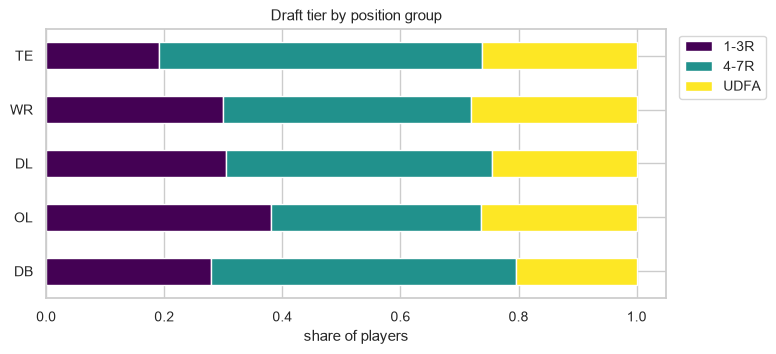

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
(pd.crosstab(players["combine_position"], players["draft_tier"], normalize="index")
   .reindex(POS)[["1-3R", "4-7R", "UDFA"]]
   .plot.barh(stacked=True, ax=ax, colormap="viridis"))
ax.set_xlabel("share of players"); ax.set_ylabel(""); ax.set_title("Draft tier by position group")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "game_draft_tier_by_position")

## 3. player_career_successes — 커리어 결과 (간단히)
양성 라벨(All-Pro, Pro Bowl)이 극소수라 분류 타깃으로는 쓰기 어렵다는 점만 확인한다.

In [8]:
career = pd.read_csv(config.RAW_FILES["player_career_successes"])
print(career.shape)
display(career.describe().T.round(1))
career[["ap_all_pro_1st_team", "ap_all_pro_2nd_team", "pro_bowl_original_ballot"]].gt(0).sum().to_frame("n_players")

(510, 9)


,count,mean,std,min,25%,50%,75%,max
nfl_id,510.0,57331.3,979.5,55867.0,56273.5,57290.0,58302.8,59278.0
career_offensive_snaps,510.0,327.4,632.4,0.0,0.0,0.0,361.8,3303.0
career_defensive_snaps,510.0,234.3,492.1,0.0,0.0,0.0,220.5,2666.0
career_special_teams_snaps,510.0,113.5,156.2,0.0,5.0,53.0,147.8,957.0
career_games_active,510.0,21.7,16.3,0.0,6.2,17.0,34.0,51.0
career_games_started,510.0,7.9,11.5,0.0,0.0,2.0,12.0,50.0
ap_all_pro_1st_team,510.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0
ap_all_pro_2nd_team,510.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0
pro_bowl_original_ballot,510.0,0.0,0.2,0.0,0.0,0.0,0.0,2.0


,n_players
ap_all_pro_1st_team,6
ap_all_pro_2nd_team,2
pro_bowl_original_ballot,11


## 4. game_tracking 1회 패스 (약 2GB → 요약 테이블)
3개 파일에서 `game_id, play_id, nfl_id, s, a, event` 6개 컬럼만 chunk로 읽어 다음을 만든다. 원본 재읽기는 이 셀 한 번뿐.
- `seg`: (경기, 플레이, 선수) 세그먼트별 프레임 수 · 최고속도 · 최대가속 (≈ 31만 행)
- `hist_s`, `hist_a`: 전체 프레임의 속도·가속 히스토그램 (분위수·임계값 분석용)
- `ev_counts`: 이벤트 종류별 프레임 수

로컬 3GB 메모리 기기에서 약 30초. Colab에서 Drive로 읽으면 몇 분 걸릴 수 있다.

In [9]:
TRK_COLS = ["game_id", "play_id", "nfl_id", "s", "a", "event"]
TRK_DTYPES = {"game_id": "int64", "play_id": "int32", "nfl_id": "int32", "s": "float32", "a": "float32"}
SEG_KEY = ["game_id", "play_id", "nfl_id"]
S_BINS = np.arange(0, 30.0001, 0.05)     # yd/s, 0.05 해상도
A_BINS = np.arange(0, 60.0001, 0.1)      # yd/s², 0.1 해상도


def tracking_pass(files, chunksize=config.TRACKING_CHUNKSIZE):
    hist_s = np.zeros(len(S_BINS) - 1, dtype=np.int64)
    hist_a = np.zeros(len(A_BINS) - 1, dtype=np.int64)
    parts, evs = [], []
    for name, path in files.items():
        t0, n = time.time(), 0
        for ch in pd.read_csv(path, usecols=TRK_COLS, dtype=TRK_DTYPES, chunksize=chunksize):
            n += len(ch)
            hist_s += np.histogram(ch["s"].dropna().clip(0, S_BINS[-1] - 1e-6), S_BINS)[0]
            hist_a += np.histogram(ch["a"].dropna().clip(0, A_BINS[-1] - 1e-6), A_BINS)[0]
            parts.append(ch.groupby(SEG_KEY).agg(n_frames=("s", "size"),
                                                 s_max=("s", "max"), a_max=("a", "max")))
            evs.append(ch["event"].value_counts())
        print(f"{path.name}: {n:,} frames, {time.time() - t0:.0f}s")
    # chunk 경계에 걸친 세그먼트를 다시 합친다
    seg = (pd.concat(parts).groupby(level=SEG_KEY)
             .agg(n_frames=("n_frames", "sum"), s_max=("s_max", "max"), a_max=("a_max", "max"))
             .reset_index())
    ev_counts = pd.concat(evs).groupby(level=0).sum().sort_values(ascending=False)
    return seg, hist_s, hist_a, ev_counts


seg, hist_s, hist_a, ev_counts = tracking_pass(config.GAME_TRACKING_FILES)
print("세그먼트:", f"{len(seg):,}", "| 선수:", seg["nfl_id"].nunique(), "| 총 프레임:", f"{hist_s.sum():,}")

game_tracking_2023.csv: 3,665,443 frames, 2s
game_tracking_2024.csv: 7,827,944 frames, 4s
game_tracking_2025.csv: 11,160,903 frames, 7s
세그먼트: 314,944 | 선수: 497 | 총 프레임: 22,654,290


In [10]:
# 시즌 · 경기 유형 · 드래프트 정보 부착
seg = (seg.merge(games[["game_id", "season", "season_type"]], on="game_id", how="left")
          .merge(players[["nfl_id", "draft_year", "combine_position", "draft_tier"]], on="nfl_id", how="left"))
seg["rookie"] = seg["season"] == seg["draft_year"]
print("games 매칭 실패:", seg["season"].isna().sum(), "| players 매칭 실패:", seg["draft_year"].isna().sum())

display(seg.groupby(["season", "season_type"]).agg(segments=("nfl_id", "size"), players=("nfl_id", "nunique"))
           .unstack()[[("segments", t) for t in ["PRE", "REG", "POST"]] + [("players", t) for t in ["PRE", "REG", "POST"]]])
seg["n_frames"].describe().round(1).to_frame("frames per segment").T

games 매칭 실패: 0 | players 매칭 실패: 0


segments               players          
season_type      PRE     REG  POST     PRE  REG POST
season                                              
2023           10207   39146  1558     150  122   31
2024           18210   86219  4291     296  247   75
2025           22375  125742  7196     420  353  115

,count,mean,std,min,25%,50%,75%,max
frames per segment,314944.0,71.9,17.1,9.0,61.0,69.0,80.0,688.0


## 5. 키 정합성 — `nfl_id` 교집합
계획서 기대값: players 510 / combine_results 510 / career 510 / player_play 497 / 루키 시즌 경기 트래킹 492.

In [11]:
pp_ids = pd.read_csv(config.RAW_FILES["player_play"], usecols=["nfl_id"])["nfl_id"]
ID_SETS = {
    "players": set(players["nfl_id"]),
    "combine_results": set(cr["nfl_id"]),
    "career": set(career["nfl_id"]),
    "player_play": set(pp_ids),
    "tracking_any_season": set(seg["nfl_id"]),
    "tracking_rookie_season": set(seg.loc[seg["rookie"], "nfl_id"]),
}
base = ID_SETS["players"]
key_tbl = pd.DataFrame({
    "n_ids": {k: len(v) for k, v in ID_SETS.items()},
    "missing_vs_players": {k: len(base - v) for k, v in ID_SETS.items()},
    "extra_vs_players": {k: len(v - base) for k, v in ID_SETS.items()},
})
save_table(key_tbl, "game_key_integrity")
key_tbl

saved → reports/tables/1_game_key_integrity.csv


,n_ids,missing_vs_players,extra_vs_players
players,510,0,0
combine_results,510,0,0
career,510,0,0
player_play,497,13,0
tracking_any_season,497,13,0
tracking_rookie_season,492,18,0


In [12]:
# 어느 한 곳에라도 빠진 선수 목록 — Stage 4 조인 시 행이 사라지는 선수들
flags = pd.DataFrame({k: players["nfl_id"].isin(v) for k, v in ID_SETS.items()})
flags.insert(0, "nfl_id", players["nfl_id"])
missing = (flags[~flags.drop(columns="nfl_id").all(axis=1)]
           .merge(players[["nfl_id", "display_name", "combine_position", "draft_year", "draft_tier"]], on="nfl_id"))
print(f"한 곳 이상 누락: {len(missing)}명")
save_table(missing, "game_missing_players", index=False)
missing.drop(columns=["players", "combine_results", "career"])

한 곳 이상 누락: 18명
saved → reports/tables/1_game_missing_players.csv


,nfl_id,player_play,tracking_any_season,tracking_rookie_season,display_name,combine_position,draft_year,draft_tier
0,56023,True,True,False,Daniel Scott,DB,2023,4-7R
1,56648,False,False,False,Ikenna Enechukwu,DL,2023,UDFA
2,56363,False,False,False,Leonard Taylor,TE,2023,UDFA
3,56497,True,True,False,Jalen Redmond,DL,2023,UDFA
4,57353,True,True,False,Nathan Thomas,OL,2024,4-7R
5,57361,True,True,False,Tahj Washington,WR,2024,4-7R
6,57374,True,True,False,K.T. Leveston,OL,2024,4-7R
7,57743,False,False,False,Trajan Jeffcoat,DL,2024,UDFA
8,57660,False,False,False,Lideatrick Griffin,WR,2024,UDFA
9,58293,False,False,False,Caleb Ransaw,DB,2025,1-3R


## 6. 루키 시즌 정의 · 노출량
루키 시즌 = `season == draft_year`. 2025 드래프트는 2025 시즌만 있으므로 루키 시즌 = 유일한 시즌.
노출량은 트래킹 세그먼트 수(= 그 선수가 트래킹에 잡힌 플레이 수)로 본다.

In [13]:
expo = (seg[seg["rookie"]].groupby(["nfl_id", "season_type"]).size()
           .unstack(fill_value=0).reindex(columns=["PRE", "REG", "POST"], fill_value=0))
expo = (players[["nfl_id", "combine_position", "draft_tier"]]
          .merge(expo, left_on="nfl_id", right_index=True, how="left").fillna({"PRE": 0, "REG": 0, "POST": 0}))
expo["REG_POST"] = expo["REG"] + expo["POST"]
expo["pre_share"] = expo["PRE"] / (expo["PRE"] + expo["REG_POST"]).replace(0, np.nan)
expo["low_exposure"] = expo["REG_POST"] < config.MIN_PLAYS_EXPOSURE
expo["no_rookie_data"] = (expo["PRE"] + expo["REG_POST"]) == 0

expo_tbl = expo.groupby("combine_position").agg(
    n_players=("nfl_id", "size"),
    no_rookie_data=("no_rookie_data", "sum"),
    median_REG_POST=("REG_POST", "median"),
    median_pre_share=("pre_share", "median"),
    low_exposure=("low_exposure", "sum"),
).reindex(POS)
save_table(expo_tbl.round(3), "game_rookie_exposure_by_position")
print(f"최소 노출 기준: 정규+포스트시즌 {config.MIN_PLAYS_EXPOSURE}플레이")
expo_tbl

saved → reports/tables/1_game_rookie_exposure_by_position.csv
최소 노출 기준: 정규+포스트시즌 50플레이


,n_players,no_rookie_data,median_REG_POST,median_pre_share,low_exposure
combine_position,,,,,
DB,122,5,157.5,0.286957,49
OL,121,3,111.0,0.333760,52
DL,118,4,135.5,0.337762,42
WR,107,2,94.0,0.261261,42
TE,42,4,52.5,0.231249,21


saved → reports/figures/1_game_rookie_exposure.png


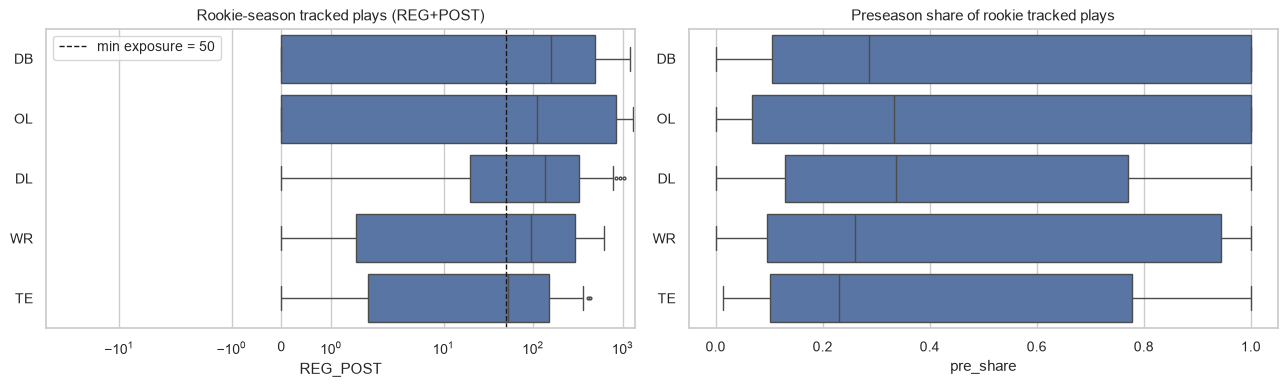

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=expo, x="REG_POST", y="combine_position", order=POS, ax=axes[0], fliersize=2)
axes[0].axvline(config.MIN_PLAYS_EXPOSURE, color="k", ls="--", lw=1, label=f"min exposure = {config.MIN_PLAYS_EXPOSURE}")
axes[0].set_xscale("symlog"); axes[0].set_title("Rookie-season tracked plays (REG+POST)"); axes[0].legend(); axes[0].set_ylabel("")
sns.boxplot(data=expo, x="pre_share", y="combine_position", order=POS, ax=axes[1], fliersize=2)
axes[1].set_title("Preseason share of rookie tracked plays"); axes[1].set_ylabel("")
fig.tight_layout()
save_fig(fig, "game_rookie_exposure")

## 7. 트래킹 세그먼트 구조 (2023 앞부분 샘플)
세그먼트 하나 = 한 선수의 한 플레이. 스냅 전후 구간 길이와 주요 이벤트 시점을 본다.

In [15]:
display(ev_counts.head(20).to_frame("frames (all seasons)"))

sample = pd.read_csv(config.GAME_TRACKING_FILES[2023], nrows=1_500_000)
sample["time"] = pd.to_datetime(sample["time"])
sample = sample.sort_values(SEG_KEY + ["time"])
print("샘플:", f"{len(sample):,} frames /", f"{sample.groupby(SEG_KEY).ngroups:,} segments")

,frames (all seasons)
event,
ball_snap,314278
pass_forward,187479
first_contact,184368
tackle,184269
pass_arrived,141322
pass_outcome_caught,113171
handoff,92594
pass_outcome_incomplete,64869
play_action,51855


샘플: 1,500,000 frames / 20,878 segments


In [16]:
g = sample.groupby(SEG_KEY)["time"]
t_snap = sample[sample["event"] == "ball_snap"].groupby(SEG_KEY)["time"].min()
t_pass = sample[sample["event"] == "pass_forward"].groupby(SEG_KEY)["time"].min()
timing = pd.DataFrame({"t0": g.min(), "t1": g.max()}).join(t_snap.rename("snap")).join(t_pass.rename("pass"))
timing["pre_snap_s"] = (timing["snap"] - timing["t0"]).dt.total_seconds()
timing["post_snap_s"] = (timing["t1"] - timing["snap"]).dt.total_seconds()
timing["snap_to_pass_s"] = (timing["pass"] - timing["snap"]).dt.total_seconds()
print("ball_snap 있는 세그먼트 비율:", round(timing["snap"].notna().mean(), 4),
      "| pass_forward 있는 비율:", round(timing["pass"].notna().mean(), 4))
timing[["pre_snap_s", "post_snap_s", "snap_to_pass_s"]].describe().round(2)

ball_snap 있는 세그먼트 비율: 0.9978 | pass_forward 있는 비율: 0.6163


,pre_snap_s,post_snap_s,snap_to_pass_s
count,20833.00,20833.00,12864.00
mean,0.95,6.14,2.82
std,0.06,1.70,1.09
min,0.00,0.20,0.10
25%,0.90,5.00,2.10
50%,1.00,5.90,2.60
75%,1.00,7.00,3.30
max,1.00,23.90,12.30


## 8. 경기 트래킹 속도·가속 분포와 글리치 임계값
01a에서 컴바인 PLAYER 데이터에는 임계값을 넘는 프레임이 없었다 → **임계값은 여기(경기 트래킹)에서 정한다**. Stage 3 타깃(`g_smax_top5mean`, `g_amax_p99`)이 이 값에 직접 영향을 받는다.
후보값 `SPEED_GLITCH_YDS = 12.5`, `ACCEL_GLITCH_YDS2 = 12.0`. 참고: NFL 경기 최고속도 기록은 약 22~23 mph(≈ 10.8~11.2 yd/s).

In [17]:
def hist_quantile(hist, bins, q):
    cdf = np.cumsum(hist) / hist.sum()
    return bins[np.searchsorted(cdf, q) + 1]      # 해당 bin의 위쪽 경계 (근사값)


S_TH, A_TH = config.SPEED_GLITCH_YDS, config.ACCEL_GLITCH_YDS2
qs = [0.5, 0.9, 0.99, 0.999, 0.9999, 0.99999]
pct = pd.DataFrame({
    "s (yd/s)": [hist_quantile(hist_s, S_BINS, q) for q in qs] + [seg["s_max"].max()],
    "a (yd/s²)": [hist_quantile(hist_a, A_BINS, q) for q in qs] + [seg["a_max"].max()],
}, index=[f"p{q*100:g}" for q in qs] + ["max"]).round(2)
display(pct)
save_table(pct, "game_speed_accel_percentiles")

over = pd.DataFrame({
    "frames_over": [hist_s[S_BINS[:-1] >= S_TH].sum(), hist_a[A_BINS[:-1] >= A_TH].sum()],
    "segments_over": [(seg["s_max"] > S_TH).sum(), (seg["a_max"] > A_TH).sum()],
    "players_over": [seg.loc[seg["s_max"] > S_TH, "nfl_id"].nunique(), seg.loc[seg["a_max"] > A_TH, "nfl_id"].nunique()],
}, index=[f"s > {S_TH}", f"a > {A_TH}"])
over["frames_share"] = over["frames_over"] / hist_s.sum()
over

,s (yd/s),a (yd/s²)
p50,2.10,1.40
p90,5.60,3.30
p99,8.20,5.30
p99.9,9.40,6.70
p99.99,10.10,7.90
p99.999,10.75,10.30
max,16.88,33.76


saved → reports/tables/1_game_speed_accel_percentiles.csv


,frames_over,segments_over,players_over,frames_share
s > 12.5,87,9,7,0.000004
a > 12.0,69,27,21,0.000003


saved → reports/figures/1_game_speed_accel_hist.png


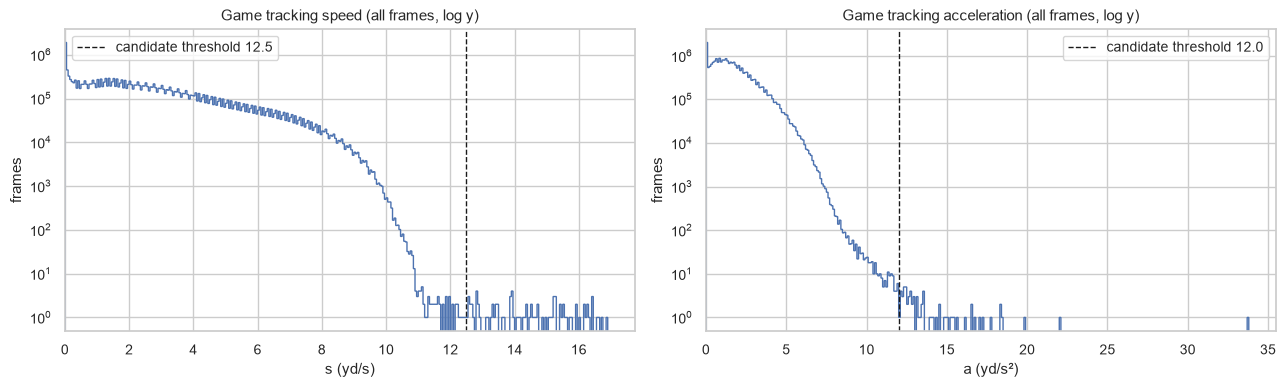

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, h, b, th, lab in [(axes[0], hist_s, S_BINS, S_TH, "s (yd/s)"), (axes[1], hist_a, A_BINS, A_TH, "a (yd/s²)")]:
    ax.stairs(h, b)
    ax.axvline(th, color="k", ls="--", lw=1, label=f"candidate threshold {th}")
    ax.set_yscale("log"); ax.set_xlabel(lab); ax.set_ylabel("frames"); ax.legend()
    ax.set_xlim(0, b[np.nonzero(h)[0].max() + 1] * 1.05)
axes[0].set_title("Game tracking speed (all frames, log y)")
axes[1].set_title("Game tracking acceleration (all frames, log y)")
fig.tight_layout()
save_fig(fig, "game_speed_accel_hist")

saved → reports/figures/1_game_play_max_speed_by_position.png


,game_id,play_id,nfl_id,n_frames,s_max,a_max,season,season_type,draft_year,combine_position,draft_tier,rookie
220516,2025101205,1289,57155,90,14.39,33.758999,2025,REG,2024,WR,1-3R,False
98238,2024102006,3650,57145,49,13.87,22.020000,2024,REG,2024,DB,1-3R,True
44492,2023123103,2174,55978,72,11.98,18.330000,2023,REG,2023,DB,4-7R,True
11422,2023091011,614,56052,57,12.67,18.320000,2023,REG,2023,WR,4-7R,True
267982,2025113003,3254,58298,59,12.83,16.549999,2025,REG,2025,DB,1-3R,True
300233,2026010300,1114,58413,75,11.01,16.120001,2025,REG,2025,WR,4-7R,True
11460,2023091011,1759,56075,78,8.86,15.600000,2023,REG,2023,WR,4-7R,True
186600,2025090708,2203,55928,71,7.46,15.360000,2025,REG,2023,WR,1-3R,False
51907,2024080951,957,56090,42,11.56,15.220000,2024,PRE,2023,OL,4-7R,False
109236,2024110310,2576,56347,96,10.60,14.810000,2024,REG,2023,DB,UDFA,False


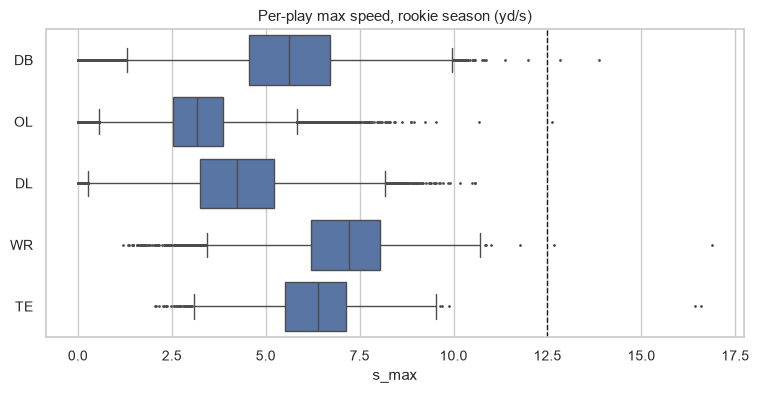

In [19]:
# 세그먼트 최고속도 분포 (포지션 그룹별) — 상식 검증: WR·DB > TE > DL > OL
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=seg[seg["rookie"]], x="s_max", y="combine_position", order=POS, ax=ax, fliersize=1)
ax.axvline(S_TH, color="k", ls="--", lw=1)
ax.set_title("Per-play max speed, rookie season (yd/s)"); ax.set_ylabel("")
save_fig(fig, "game_play_max_speed_by_position")

# 임계값을 넘는 세그먼트 — 실제 글리치인지 사례로 확인
seg[(seg["s_max"] > S_TH) | (seg["a_max"] > A_TH)].sort_values("a_max", ascending=False).head(15)

> **결정 필요**: 위 분위수·히스토그램·사례를 근거로 경기 트래킹용 `SPEED_GLITCH_YDS`, `ACCEL_GLITCH_YDS2`를 정해 `config.py`에 반영한다. 임계값을 넘는 프레임 비율이 극히 작다면, 타깃을 "플레이별 최고속도 상위 5개 평균"처럼 견고하게 정의한 계획서 방침이 임계값 선택의 영향을 거의 받지 않는다는 근거로도 쓸 수 있다.

## 9. player_play — 포지션 그룹별 NGS 컬럼 채움률
T4 생산성 지표(WR/TE 타깃·분리, OL 압박 허용, DL 패스러시, DB 커버리지)를 어떤 컬럼으로 정의할 수 있는지의 근거. `play_description`(긴 텍스트)은 메모리 절약을 위해 읽지 않는다.

In [20]:
pp = pd.read_csv(config.RAW_FILES["player_play"], usecols=lambda c: c != "play_description")
pp = (pp.merge(games[["game_id", "season", "season_type"]], on="game_id", how="left")
        .merge(players[["nfl_id", "draft_year", "combine_position"]], on="nfl_id", how="left"))
pp["rookie"] = pp["season"] == pp["draft_year"]
print(pp.shape, f"| {pp.memory_usage(deep=True).sum() / 1e6:.0f} MB",
      "| (game, play, nfl_id) 중복:", pp.duplicated(["game_id", "play_id", "nfl_id"]).sum())
display(pd.crosstab(pp["season"], pp["season_type"])[["PRE", "REG", "POST"]])

(314197, 68) | 243 MB | (game, play, nfl_id) 중복: 0


season_type,PRE,REG,POST
season,,,
2023,10407,38788,1560
2024,18611,85562,4351
2025,22741,124919,7258


saved → reports/figures/1_game_player_play_fill_by_position.png
saved → reports/tables/1_game_player_play_fill_by_position.csv


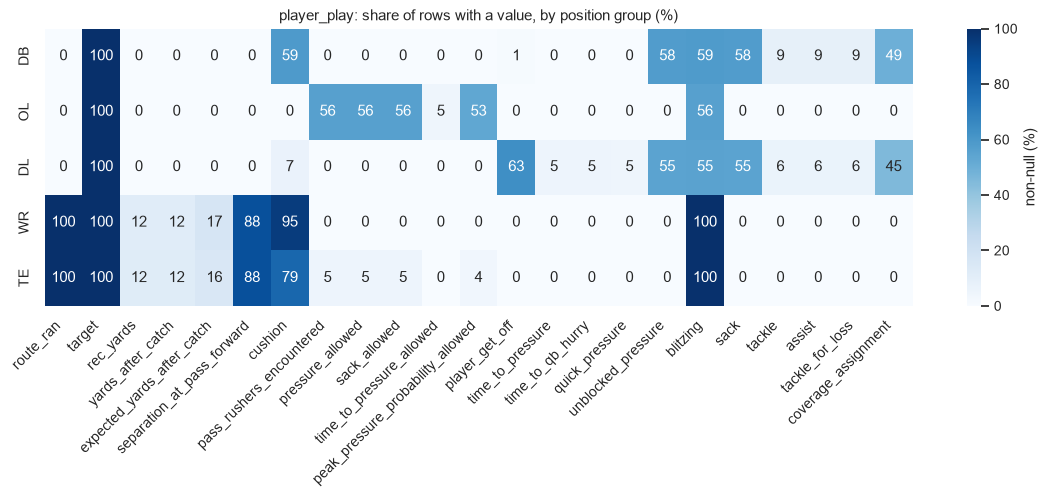

In [21]:
NGS_COLS = [
    "route_ran", "target", "rec_yards", "yards_after_catch", "expected_yards_after_catch",
    "separation_at_pass_forward", "cushion",
    "pass_rushers_encountered", "pressure_allowed", "sack_allowed", "time_to_pressure_allowed",
    "peak_pressure_probability_allowed",
    "player_get_off", "time_to_pressure", "time_to_qb_hurry", "quick_pressure", "unblocked_pressure",
    "blitzing", "sack", "tackle", "assist", "tackle_for_loss",
    "coverage_assignment",
]
fill = pp.groupby("combine_position")[NGS_COLS].agg(lambda s: s.notna().mean()).reindex(POS)

fig, ax = plt.subplots(figsize=(14, 3.6))
sns.heatmap(fill * 100, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "non-null (%)"}, ax=ax)
ax.set_title("player_play: share of rows with a value, by position group (%)"); ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
save_fig(fig, "game_player_play_fill_by_position")
save_table(fill.round(3), "game_player_play_fill_by_position")

불리언 컬럼(`target`, `pressure_allowed` 등)은 해당 없는 포지션에도 FALSE로 채워져 있을 수 있다. 채움률이 높아도 **값이 실제로 의미 있는지**(TRUE 비율)를 같이 본다.

In [22]:
BOOL_COLS = ["target", "pressure_allowed", "sack_allowed", "quick_pressure", "unblocked_pressure", "blitzing", "sack", "tackle"]
true_rate = (pp[BOOL_COLS].astype("float").groupby(pp["combine_position"]).mean().reindex(POS) * 100).round(1)
display(true_rate)
# 같은 그룹 안에서도 플레이마다 맡는 위치가 다르다 (DL = EDGE / INTERIOR_LINE 등)
pos_line = pd.crosstab(pp["lined_up_position"], pp["combine_position"])[POS]
save_table(pos_line, "game_lined_up_by_position")
pos_line

,target,pressure_allowed,sack_allowed,quick_pressure,unblocked_pressure,blitzing,sack,tackle
combine_position,,,,,,,,
DB,0.0,0.0,0.0,62.3,0.4,2.6,0.1,67.0
OL,0.0,8.2,1.0,NaN,0.0,0.0,0.0,75.5
DL,0.0,NaN,NaN,29.6,0.8,95.0,1.2,52.3
WR,18.8,8.3,0.9,NaN,NaN,0.0,NaN,94.6
TE,16.8,6.7,0.5,NaN,NaN,0.0,NaN,84.0


saved → reports/tables/1_game_lined_up_by_position.csv


combine_position,DB,OL,DL,WR,TE
lined_up_position,,,,,
BOX_SAFETY,266,0,0,0,0
C,0,14959,0,0,0
CB,34980,1,36,0,0
EDGE,1567,0,36831,0,0
EXTRA_OL,0,1,0,0,0
FB,5,46,0,48,129
G,0,48507,0,0,0
HIGH_SAFETY,25598,10,0,0,0
INTERIOR_LINE,129,0,30172,0,0


## 10. 루키 정규시즌 스냅 → `starter_flag` 기준 미리보기
계획서 T4: `rookie_snaps_reg` = 정규시즌 player_play 행 수, `starter_flag` = 포지션 그룹 내 상위 1/3. 페널티로 무효된 플레이 포함 여부도 비교한다. 스냅이 0인 선수도 그룹 분모에 포함한다.

In [23]:
reg = pp[pp["rookie"] & (pp["season_type"] == "REG")]
snaps = players[["nfl_id", "combine_position", "draft_tier"]].copy()
snaps["snaps_reg"] = snaps["nfl_id"].map(reg.groupby("nfl_id").size()).fillna(0).astype(int)
snaps["snaps_reg_valid"] = snaps["nfl_id"].map(
    reg[reg["play_nullified_by_penalty"] != "Y"].groupby("nfl_id").size()).fillna(0).astype(int)
snaps["games_reg"] = snaps["nfl_id"].map(reg.groupby("nfl_id")["game_id"].nunique()).fillna(0).astype(int)

q = 1 - config.STARTER_TOP_FRACTION
cut = snaps.groupby("combine_position")["snaps_reg"].quantile(q)
snaps["starter_preview"] = snaps["snaps_reg"] >= snaps["combine_position"].map(cut)

starter_tbl = snaps.groupby("combine_position").agg(
    n=("nfl_id", "size"), zero_snaps=("snaps_reg", lambda s: (s == 0).sum()),
    median_snaps=("snaps_reg", "median"), max_snaps=("snaps_reg", "max"),
    starters=("starter_preview", "sum")).reindex(POS)
starter_tbl["cut_top_third"] = cut.reindex(POS)
starter_tbl["nullified_share"] = (1 - snaps.groupby("combine_position")["snaps_reg_valid"].sum()
                                  / snaps.groupby("combine_position")["snaps_reg"].sum()).reindex(POS).round(3)
save_table(starter_tbl, "game_rookie_snaps_starter_preview")
starter_tbl

saved → reports/tables/1_game_rookie_snaps_starter_preview.csv


,n,zero_snaps,median_snaps,max_snaps,starters,cut_top_third,nullified_share
combine_position,,,,,,,
DB,122,35,145.5,1065,41,344.000000,0.041
OL,121,37,89.0,1163,40,486.000000,0.043
DL,118,24,133.0,968,39,241.000000,0.042
WR,107,27,89.0,582,36,228.666667,0.000
TE,42,9,38.0,417,14,116.333333,0.000


saved → reports/figures/1_game_rookie_snaps_ecdf.png


starter_preview,False,True
draft_tier,,
1-3R,0.26,0.74
4-7R,0.78,0.22
UDFA,0.97,0.03


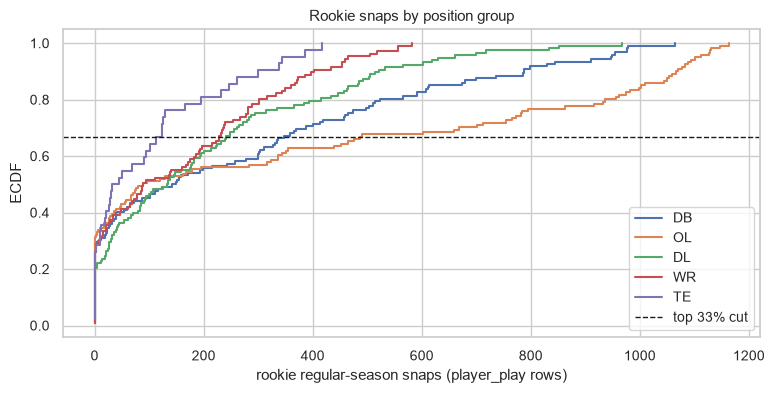

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
for p in POS:
    s = np.sort(snaps.loc[snaps["combine_position"] == p, "snaps_reg"].to_numpy())
    ax.step(s, np.arange(1, len(s) + 1) / len(s), where="post", label=p)
ax.axhline(q, color="k", ls="--", lw=1, label=f"top {config.STARTER_TOP_FRACTION:.0%} cut")
ax.set_xlabel("rookie regular-season snaps (player_play rows)"); ax.set_ylabel("ECDF")
ax.set_title("Rookie snaps by position group"); ax.legend()
save_fig(fig, "game_rookie_snaps_ecdf")

# 스냅 상위 1/3과 드래프트 티어의 관계 (Stage 7 과제 2 미리보기)
pd.crosstab(snaps["draft_tier"], snaps["starter_preview"], normalize="index").round(2)

## 11. 미리보기 — 경기 최고속도 vs 컴바인 forty (포지션 교란)
Stage 3 타깃 `g_smax_top5mean`의 **간이 버전**: 루키 시즌 정규+포스트시즌, 임계값 이하 세그먼트의 최고속도 상위 5개 평균. 정식 계산(글리치 프레임 제거 후)은 Stage 3에서 한다.
전체 상관과 포지션 그룹 내 상관을 비교한다 — 보고서·발표의 핵심 그림 후보.

In [25]:
rk = seg[seg["rookie"] & seg["season_type"].isin(["REG", "POST"]) & (seg["s_max"] <= S_TH)]
top5 = (rk.sort_values("s_max", ascending=False).groupby("nfl_id").head(config.TOP_K_PLAYS)
          .groupby("nfl_id")["s_max"].mean().rename("g_smax_top5_preview"))
spd = (cr.merge(top5, left_on="nfl_id", right_index=True)
         .merge(expo[["nfl_id", "REG_POST"]], on="nfl_id")
         .dropna(subset=["forty"]))
spd = spd[spd["REG_POST"] >= config.MIN_PLAYS_EXPOSURE]

r_all = spd["forty"].corr(spd["g_smax_top5_preview"])
r_grp = spd.groupby("combine_position")[["forty", "g_smax_top5_preview"]].corr().xs("forty", level=1)["g_smax_top5_preview"].reindex(POS)
cen = spd[["forty", "g_smax_top5_preview"]] - spd.groupby("combine_position")[["forty", "g_smax_top5_preview"]].transform("mean")
r_pooled = cen["forty"].corr(cen["g_smax_top5_preview"])

corr_tbl = pd.concat([pd.Series({"ALL (overall)": r_all, "pooled within-group": r_pooled}), r_grp]).rename("r").to_frame()
corr_tbl["n"] = [len(spd), len(spd)] + spd["combine_position"].value_counts().reindex(POS).tolist()
save_table(corr_tbl.round(3), "game_speed_vs_forty_corr")
corr_tbl.round(2)

saved → reports/tables/1_game_speed_vs_forty_corr.csv


,r,n
ALL (overall),-0.89,257
pooled within-group,-0.49,257
DB,-0.39,63
OL,-0.33,57
DL,-0.65,59
WR,-0.41,60
TE,-0.45,18


saved → reports/figures/1_game_speed_vs_forty_confounding.png


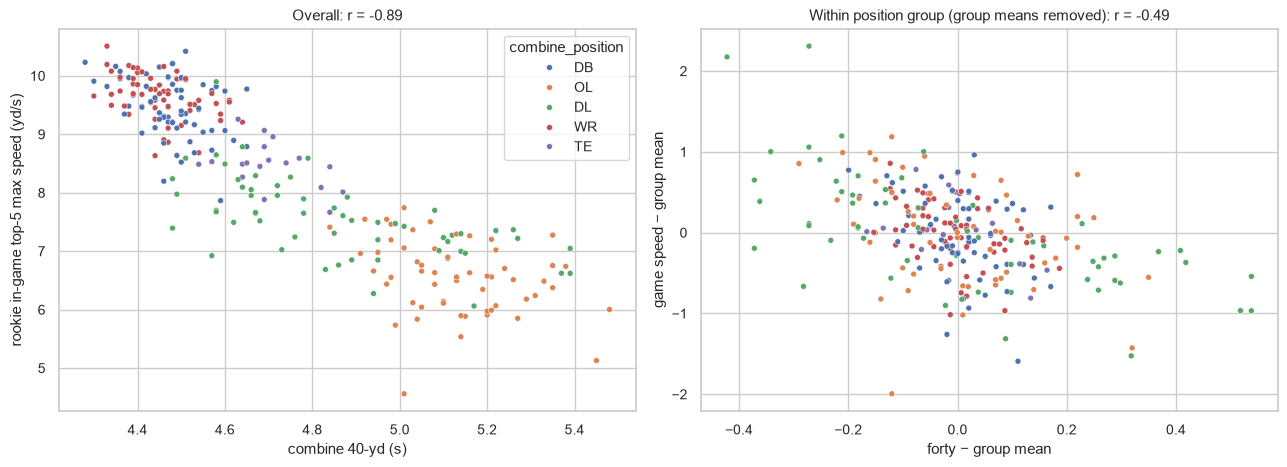

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=spd, x="forty", y="g_smax_top5_preview", hue="combine_position", hue_order=POS,
                s=18, ax=axes[0])
axes[0].set_title(f"Overall: r = {r_all:.2f}")
sns.scatterplot(x=cen["forty"], y=cen["g_smax_top5_preview"], hue=spd["combine_position"], hue_order=POS,
                s=18, ax=axes[1], legend=False)
axes[1].set_title(f"Within position group (group means removed): r = {r_pooled:.2f}")
axes[0].set_xlabel("combine 40-yd (s)"); axes[0].set_ylabel("rookie in-game top-5 max speed (yd/s)")
axes[1].set_xlabel("forty − group mean"); axes[1].set_ylabel("game speed − group mean")
fig.tight_layout()
save_fig(fig, "game_speed_vs_forty_confounding")

## 12. 요약 · 결정 사항 (→ `reports/eda.md` 경기 절)

**확인한 사실**
- (1절) 시즌 구성 · game_id 접두사 함정: …
- (2절) 드래프트 티어 분포, nfl_position ↔ 분석 그룹 대응: …
- (5절) 키 정합성: …
- (6절) 루키 시즌 노출량 · 프리시즌 비중 · 저노출 선수 수: …
- (7절) 세그먼트 구조(스냅 전/후 길이, 스냅→패스): …
- (8절) 경기 속도·가속 분위수, 임계값 초과 프레임: …
- (9절) 포지션별로 쓸 수 있는 NGS 컬럼: …
- (11절) forty vs 경기 속도 — 전체 r vs 그룹 내 r: …

**결정 사항 (config.py · 계획서에 반영)**
| 항목 | 후보 | 결정 | 근거 |
|---|---|---|---|
| season 부여 | games 조인 | | 1절 |
| 루키 시즌 | `season == draft_year` | | 5·6절 |
| `SPEED_GLITCH_YDS` | 12.5 | | 8절 |
| `ACCEL_GLITCH_YDS2` | 12.0 | | 8절 |
| `MIN_PLAYS_EXPOSURE` | 50 (REG+POST) | | 6절 |
| `starter_flag` | 그룹 내 정규시즌 스냅 상위 1/3 | | 10절 |
| 무효 플레이(페널티) 포함 여부 | 포함 | | 10절 |

**Stage 3·4로 넘길 메모**
- …